# Sensor space analysis: ERP/ERF

`
Authors:
Marijn van Vliet, Britta Westner, Alexandre Gramfort, Denis A. Engemann
`

In [1]:
# This makes figures appear inside the notebook instead of in a new window.
%matplotlib inline

# We set the log-level of MNE-Python to 'warning' so the output is less verbose:
import mne
mne.set_log_level('error')

# Disable all warnings so they don't end up in the HTML.
import warnings
warnings.filterwarnings("ignore")

# Specify rendering backends
mne.viz.set_browser_backend("qt")

## Setup

We already know this part from last time:
 

In [2]:
# These are the Python packages we will use in this session.
import numpy as np  # for numerical computations
import matplotlib.pyplot as plt  # for making custom figures
import mne  # for MEG and EEG data analysis

# Change the following path to where you want to save the processed data.
processed_path = "./data/processed"

# Based on the `processed_path` you specified above, this is where the epochs should be.
epochs_fname = f"{processed_path}/sub-01/sub-01_epo.fif"
print(epochs_fname)

./data/processed/sub-01/sub-01_epo.fif


Now we can load the epochs we created during [the previous session](1-preprocessing).

In [3]:
epochs = mne.read_epochs(epochs_fname)

We can look at the epochs:

In [4]:
epochs.plot();

## Average the epochs to get ERF/ERP 

The MNE-Python [`Epochs`](https://mne.tools/stable/generated/mne.Epochs.html) object has an [`epochs.average()`](https://mne.tools/stable/generated/mne.Epochs.html#mne.Epochs.average) method to average across epochs and construct an [`Evoked`](https://mne.tools/stable/generated/mne.Evoked.html) object.

In [5]:
evoked = epochs.average()  # average across epochs to create the evoked response
print(evoked)

<Evoked | '0.17 × face/famous/first + 0.07 × face/famous/immediate + 0.10 × face/famous/long + 0.17 × face/unfamiliar/first + 0.08 × face/unfamiliar/immediate + 0.07 × face/unfamiliar/long + 0.17 × scrambled/first + 0.10 × scrambled/immediate + 0.08 × scrambled/long' (average, N=146), -0.5 – 2 s, baseline -0.5 – 0 s, 376 ch, ~9.2 MiB>


Let's look at our evoked field and evoked potential!

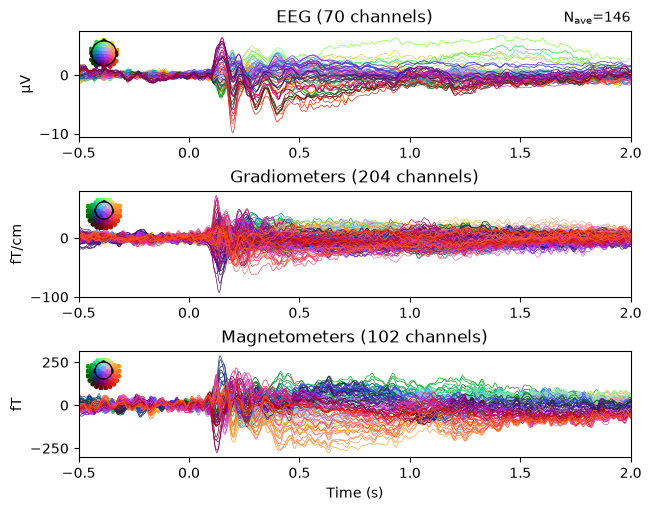

In [6]:
evoked.plot();

Let's crop the data to the -0.2 to 1 seconds interval, so we zoom in more on the experimental effect.

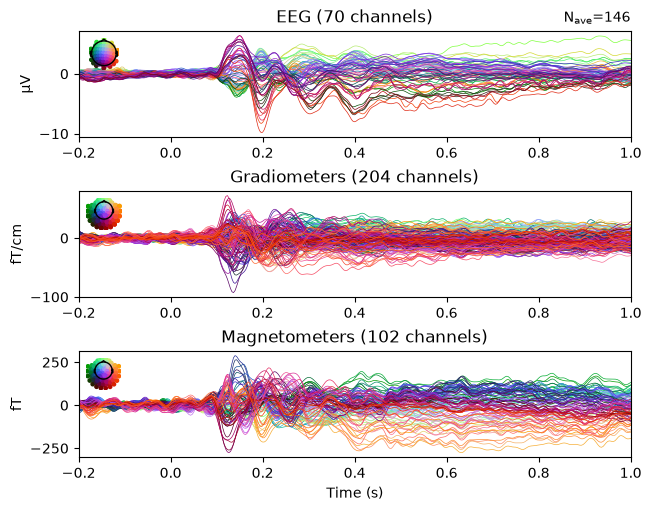

In [7]:
epochs.crop(-0.2, 1)
evoked = epochs.average()
evoked.plot();

### Explore the different conditions in the data

We have seen in the last session, that the data has different events, which mark which stimulus was shown to the participants. The event/trigger structure is as follows:
- 5, 6, 7: famous faces
- 13, 14, 15: unfamiliar faces
- 17, 18, 19: scrambled faces

We have epoched the data according to these events previously. Let's see how we can use these event codes to work with the conditions!

We first look at how we registered the events:

In [8]:
print(epochs.event_id)

{'face/famous/first': 5, 'face/famous/immediate': 6, 'face/famous/long': 7, 'face/unfamiliar/first': 13, 'face/unfamiliar/immediate': 14, 'face/unfamiliar/long': 15, 'scrambled/first': 17, 'scrambled/immediate': 18, 'scrambled/long': 19}


### Separate the conditions

Note that we used `/` separators in the event descriptions. These are inspired by file paths. For example, we can get all the epochs corresponding to "face" events:

In [9]:
print(epochs["face"])

<EpochsFIF | 96 events (all good), -0.2 – 1 s (baseline -0.5 – 0 s (baseline period was cropped after baseline correction)), ~107.8 MiB, data loaded,
 'face/famous/first': 25
 'face/famous/immediate': 10
 'face/famous/long': 14
 'face/unfamiliar/first': 25
 'face/unfamiliar/immediate': 12
 'face/unfamiliar/long': 10>


But also all the epochs where the stimulus was shown for a `long` duration:

In [10]:
print(epochs["long"])

<EpochsFIF | 35 events (all good), -0.2 – 1 s (baseline -0.5 – 0 s (baseline period was cropped after baseline correction)), ~43.8 MiB, data loaded,
 'face/famous/long': 14
 'face/unfamiliar/long': 10
 'scrambled/long': 11>


We can also select multiple events at the same time:

In [11]:
print(epochs["scrambled", "famous"])

<EpochsFIF | 99 events (all good), -0.2 – 1 s (baseline -0.5 – 0 s (baseline period was cropped after baseline correction)), ~110.9 MiB, data loaded,
 'face/famous/first': 25
 'face/famous/immediate': 10
 'face/famous/long': 14
 'scrambled/first': 25
 'scrambled/immediate': 14
 'scrambled/long': 11>


This functionality is very useful for creating contrasts between conditions. A common thing to do is to compute the evoked field in response to different conditions and compare them. The main conditions in this dataset are `famous` versus `unfamiliar` versus `scrambled`. Let's create `Evoked` objects for each of them:

In [12]:
evoked_famous = epochs["famous"].average()
evoked_unfamiliar = epochs["unfamiliar"].average()
evoked_scrambled = epochs["scrambled"].average()

print(evoked_famous)

<Evoked | '0.51 × face/famous/first + 0.20 × face/famous/immediate + 0.29 × face/famous/long' (average, N=49), -0.2 – 1 s, baseline -0.5 – 0 s (baseline period was cropped after baseline correction), 376 ch, ~8.1 MiB>


From the output we see that the `comment` field of each `Evoked` object was automatically generated from all the different event types that went into the average. This is very verbose in our case. Let's set the `evoked.comment` field to something more sensible:

In [13]:
evoked_famous.comment = "famous faces"
evoked_unfamiliar.comment = "unfamiliar faces"
evoked_scrambled.comment = "scrambled stimuli"

print(evoked_famous)

<Evoked | 'famous faces' (average, N=49), -0.2 – 1 s, baseline -0.5 – 0 s (baseline period was cropped after baseline correction), 376 ch, ~8.1 MiB>


That's better. Now to visually compare the evokeds. There are many functions for this, but the most obvious one to use is [`mne.viz.plot_compare_evokeds`](https://mne.tools/stable/generated/mne.viz.plot_compare_evokeds.html):

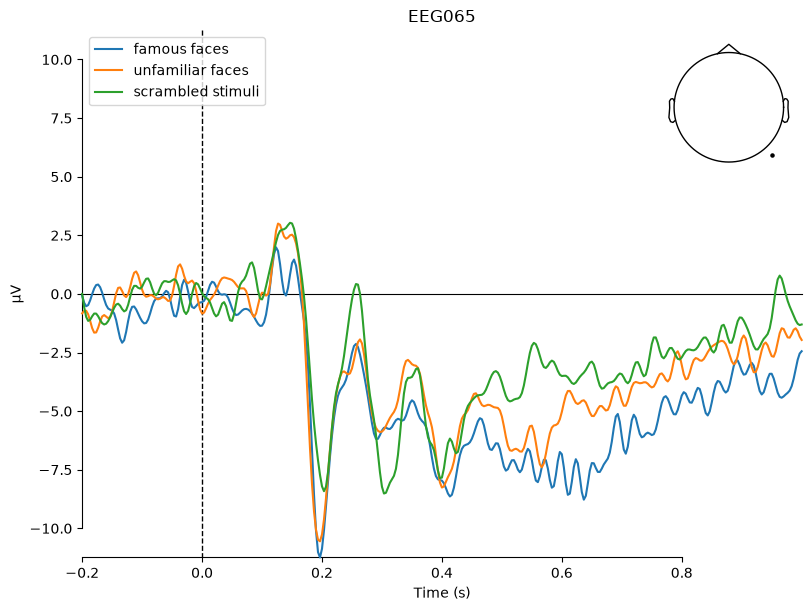

In [14]:
# Show the evoked for EEG channel 65 (in EEG we call the evoked the ERP)
mne.viz.plot_compare_evokeds([evoked_famous, evoked_unfamiliar, evoked_scrambled], picks="EEG065");

It is also possible to view all channels of a certain type in one big figure:

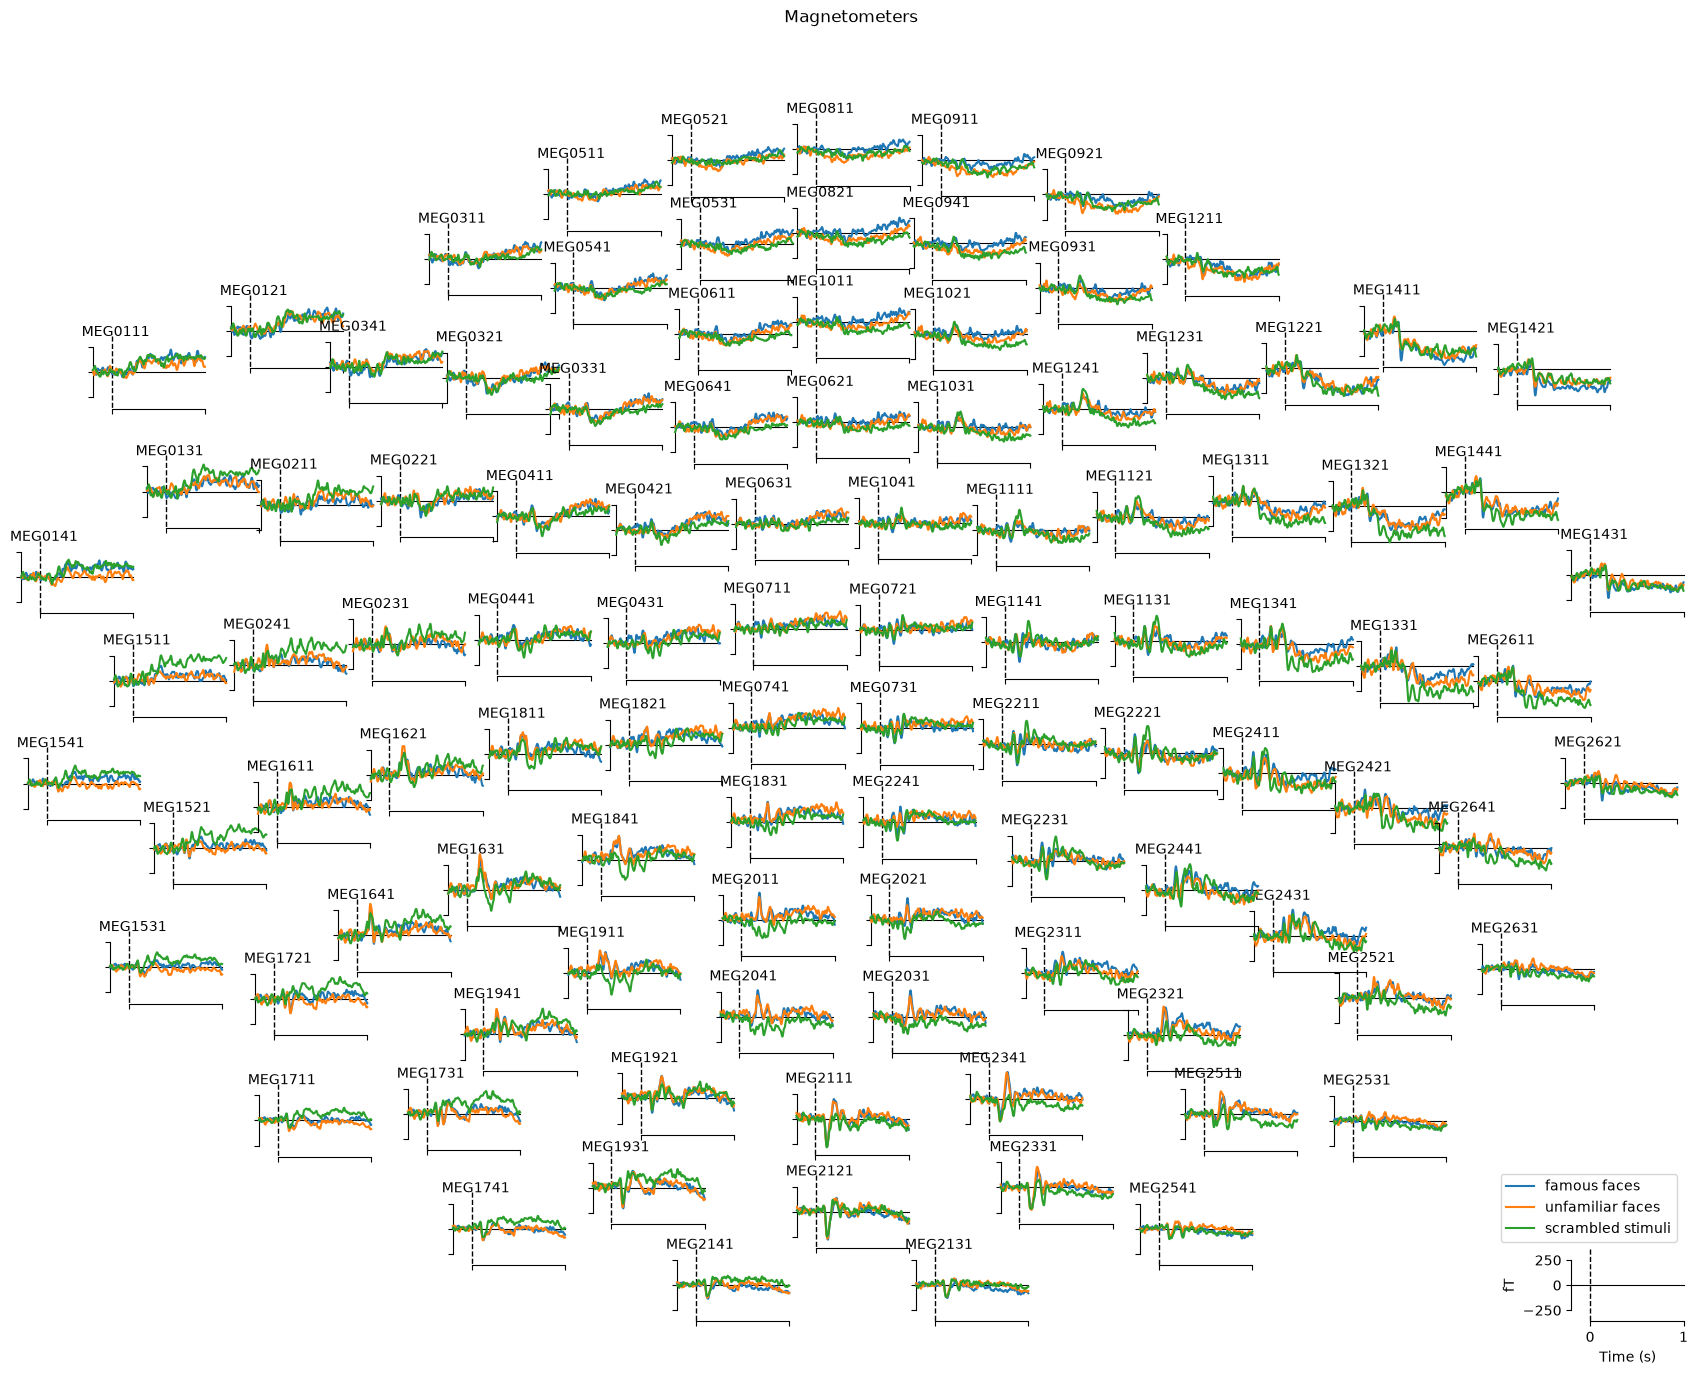

In [15]:
mne.viz.plot_compare_evokeds([evoked_famous, evoked_unfamiliar, evoked_scrambled], picks="mag", axes="topo");

<div class="alert alert-success">
    <b>EXERCISE</b>:
     <ul>
      <li>Try clicking on the plot, what happens?</li>
      <li>Can you make the same plots for gradiometers and EEG sensors?</li>
    </ul>
</div>


MNE-Python also has some definitions for groups of channels that may be useful. For example, for the MegIn VectorView machine which recorded this dataset, it has the following channel groups:

- Vertex
- Left-temporal
- Right-temporal
- Left-occipital
- Right-occipital
- Left-frontal
- Right-frontal
  
We can load these with [`mne.channels.read_vectorview_selection`](https://mne.tools/stable/generated/mne.read_vectorview_selection.html) and then use them in the `picks` argument:

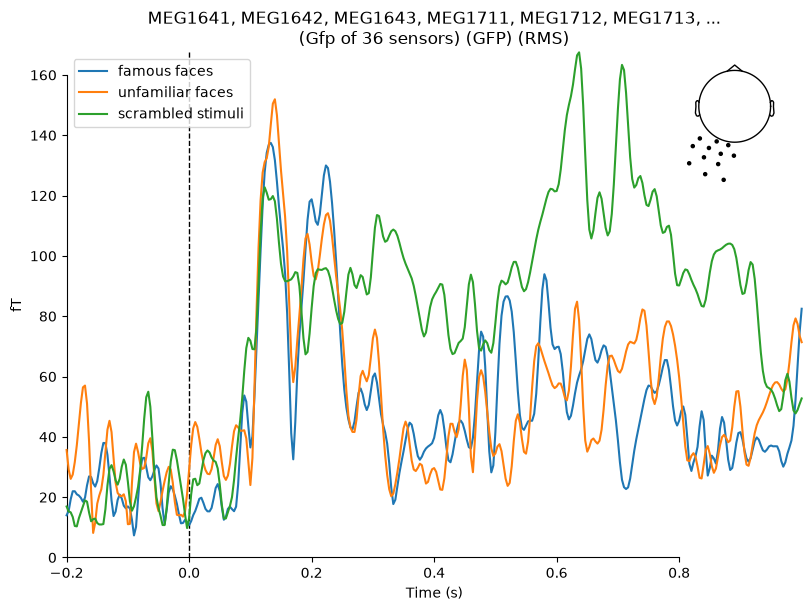

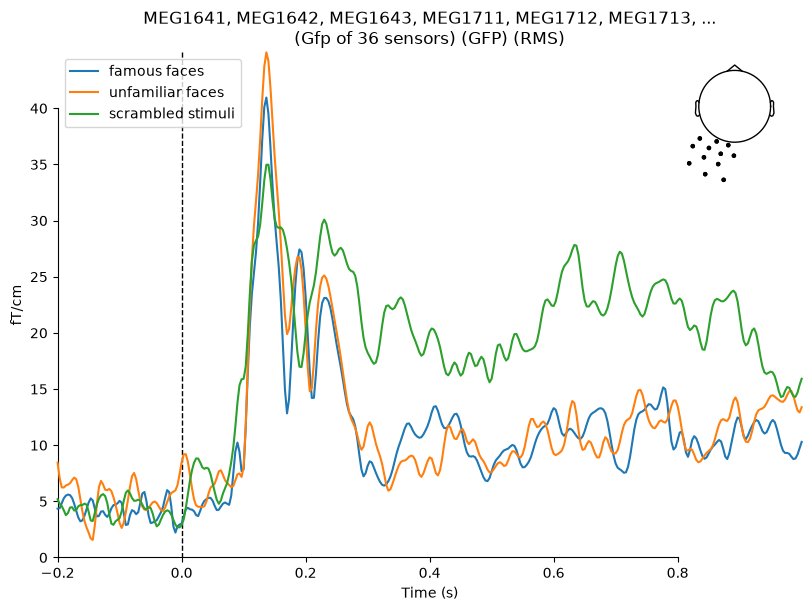

In [16]:
channel_group = mne.channels.read_vectorview_selection("Left-occipital", info=epochs.info)
mne.viz.plot_compare_evokeds([evoked_famous, evoked_unfamiliar, evoked_scrambled], picks=channel_group, show_sensors=True);

### Combining evokeds

We can use [`mne.combine_evoked`](https://mne.tools/stable/generated/mne.combine_evoked.html) to merge conditions:

In [17]:
evoked_faces = mne.combine_evoked([evoked_famous, evoked_unfamiliar], weights="nave")
print(evoked_faces)

<Evoked | '0.510 × famous faces + 0.490 × unfamiliar faces' (average, N=96.00000000000003), -0.2 – 1 s, baseline -0.5 – 0 s (baseline period was cropped after baseline correction), 376 ch, ~8.1 MiB>


You may want to set the description to something more manageable:

In [18]:
evoked_faces.comment = "all faces"
print(evoked_faces)

<Evoked | 'all faces' (average, N=96.00000000000003), -0.2 – 1 s, baseline -0.5 – 0 s (baseline period was cropped after baseline correction), 376 ch, ~8.1 MiB>


By setting the `weights` properly, we can also use this function to create a contrast between two conditions:

In [19]:
faces_vs_scrambled = mne.combine_evoked([evoked_faces, evoked_scrambled], weights=[1, -1])
faces_vs_scrambled.comment = "faces vs scrambled"

## Plot topographic maps

To get a sense of roughly where in the brain we can see a difference between the conditions, we can create topographic maps ("topomaps"), which we have seen before during the ICA part.

Next, we want to plot the topographies at the peak. We want to plot this for all channel types _and_ all conditions. To not wind up with 9 individual plots, let's see how to combine plots into one figure!

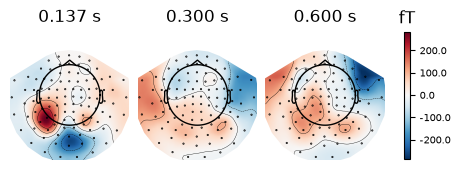

In [20]:
mne.viz.plot_evoked_topomap(evoked_famous, ch_type="mag", times=[0.137, 0.3, 0.6]);

<div class="alert alert-success">
    <b>EXERCISE</b>:
     <ul>
      <li>Can you plot the difference between faces and scrambled stimuli?</li>
    </ul>
</div>


Another quick way to create topographic maps is to use the interactive capabilities of `mne.viz.plot_evoked`:

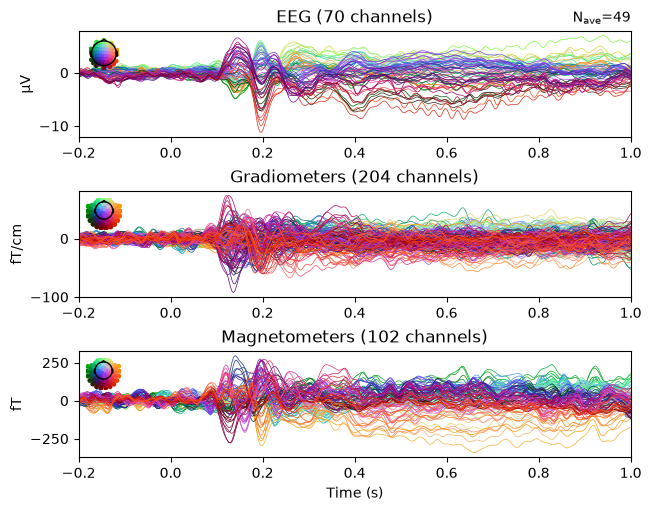

In [21]:
mne.viz.plot_evoked(evoked_famous);

<div class="alert alert-success">
    <b>EXERCISE</b>:
     <ul>
      <li>Try clicking and dragging to select a time region, what happens?</li>
    </ul>
</div>


## Write evoked data to disk

As many MNE-Python objects, the `Evoked` object has a `.save` method:

In [22]:
# Make sure the processed data folder exists
import os
os.makedirs(f"{processed_path}/sub-01", exist_ok=True)

In [23]:
evoked_famous.save(f"{processed_path}/sub-01/sub-01_famous_ave.fif", overwrite=True) 

You can also write multiple conditions into one file:

In [24]:
mne.write_evokeds(f"{processed_path}/sub-01/sub-01_ave.fif", [evoked_faces, evoked_famous, evoked_unfamiliar, evoked_scrambled], overwrite=True)

### Reading evoked from disk

You can read the data back from the stored `.fif` file:

In [25]:
evokeds_list = mne.read_evokeds(f"{processed_path}/sub-01/sub-01_ave.fif")
print(evokeds_list)

[<Evoked | 'all faces' (average, N=96), -0.2 – 1 s, baseline -0.5 – 0 s (baseline period was cropped after baseline correction), 376 ch, ~8.0 MiB>, <Evoked | 'famous faces' (average, N=49), -0.2 – 1 s, baseline -0.5 – 0 s (baseline period was cropped after baseline correction), 376 ch, ~8.0 MiB>, <Evoked | 'unfamiliar faces' (average, N=47), -0.2 – 1 s, baseline -0.5 – 0 s (baseline period was cropped after baseline correction), 376 ch, ~8.0 MiB>, <Evoked | 'scrambled stimuli' (average, N=50), -0.2 – 1 s, baseline -0.5 – 0 s (baseline period was cropped after baseline correction), 376 ch, ~8.0 MiB>]


Or give the explicit name of the averaged condition when reading in the list:

In [31]:
evoked_famous = mne.read_evokeds(f"{processed_path}/sub-01/sub-01_ave.fif", condition="famous faces")
print(evoked_famous)

<Evoked | 'famous faces' (average, N=49), -0.2 – 1 s, baseline -0.5 – 0 s (baseline period was cropped after baseline correction), 376 ch, ~8.0 MiB>


## Composing and saving figures.

The 2D figures are drawn using the [matplotlib](https://matplotlib.org) package. MNE-Python's plotting functions expose matplotlib objects such as `matplotlib.Figure` and `matplotlib.Axes`. They can be manipulated and saved using matplotlib's functionality. For example, many of MNE-Python's plotting functions take an `axes` parameter to specify where in the matplotlib figure to draw. If you are proficient in matplotlib, you can do things like this:

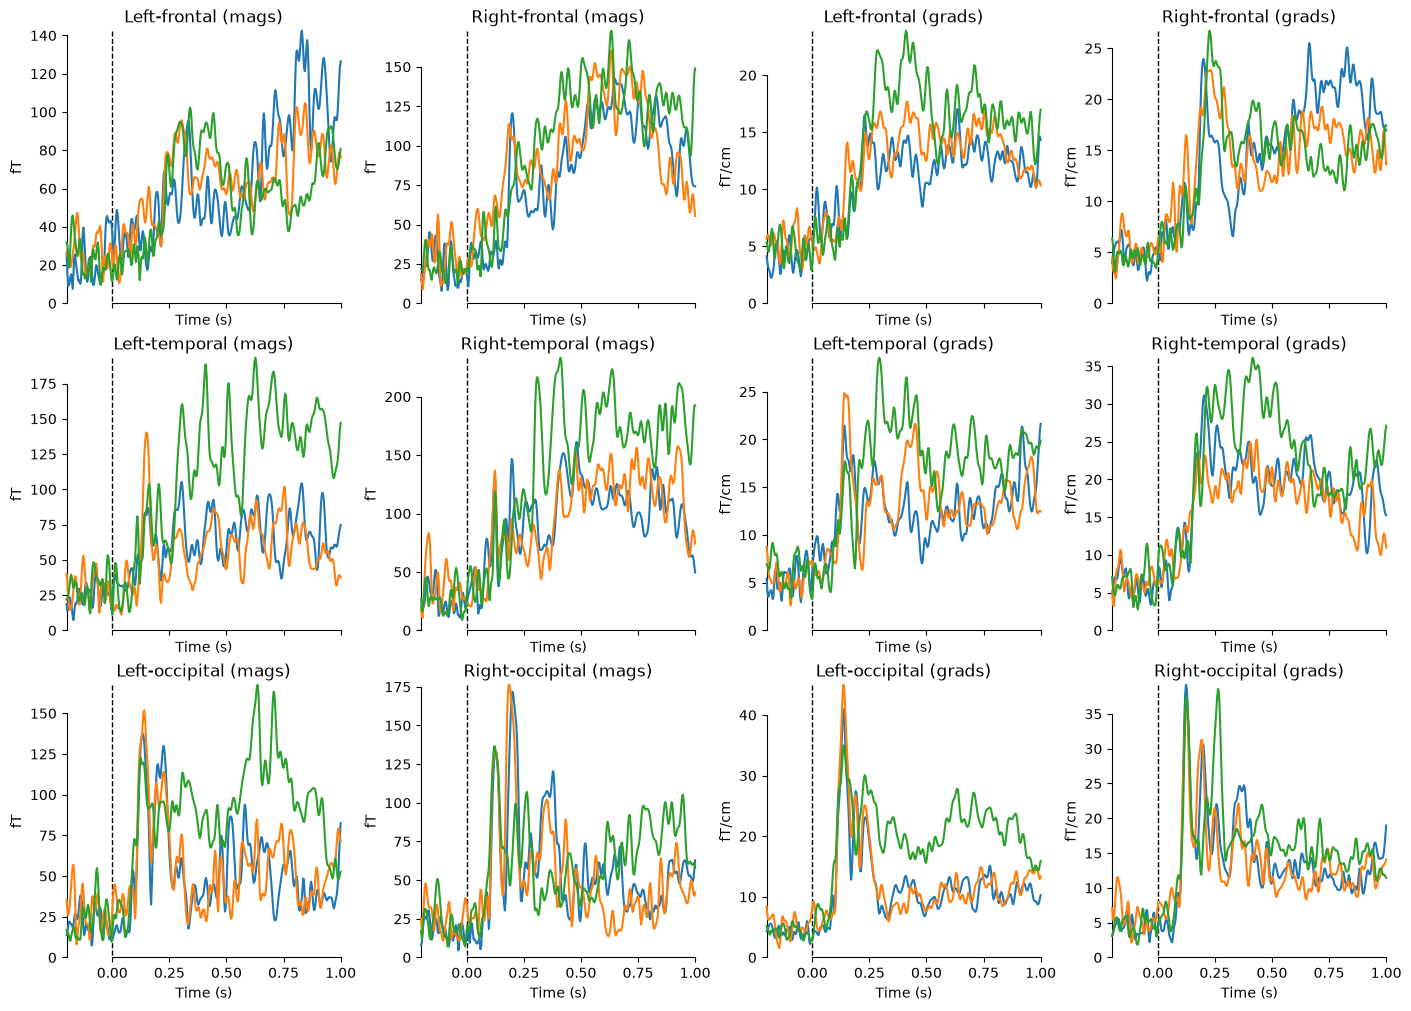

In [27]:
# Drawing of 2D figures is done with matplotlib.
import matplotlib.pyplot as plt

# Create a 3x4 grid of panels, which matplotlib calls "axes".
fig, axes = plt.subplots(nrows=3, ncols=4, sharex=True, figsize=(14, 10), layout="constrained")

# Fill the panels with evoked plots.
for row, region in enumerate(["frontal", "temporal", "occipital"]):
    for column,  hemi in enumerate(["Left", "Right"]):
        ax = axes[row][[column, column + 2]]
        channel_group = mne.channels.read_vectorview_selection(f"{hemi}-{region}", info=epochs.info)
        mne.viz.plot_compare_evokeds(
            [evoked_famous, evoked_unfamiliar, evoked_scrambled],
            picks=channel_group, legend=False, show=False,
            axes=ax  # draw in these two matplotlib axes objects
        )
        ax[0].set_title(f"{hemi}-{region} (mags)")
        ax[1].set_title(f"{hemi}-{region} (grads)")

Saving a masterpiece figure like the one above can be done either with [`plt.savefig()`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.savefig.html) or [`fig.savefig()`](https://matplotlib.org/stable/api/_as_gen/matplotlib.figure.Figure.savefig.html):

In [28]:
fig.savefig("evokeds.pdf")

## Visualizing the magnetic field

To get a better understanding of how MEG "sees" the magnetic field, we can visualize the fieldlines:

In [29]:
# get the path of the transform file
# usually, this needs to be created by manual coregistration, but we have it all ready!
extra_path = "./extra_data_mne/"
trans_fname = f"{extra_path}/source_recon/sub-01/sub-01-trans.fif"

# we also need the Freesurfer subjects direcory:
subjects_dir = f"{extra_path}/freesurfer"

In [30]:
# first make the map
maps = mne.make_field_map(evoked_famous, trans=None, ch_type="meg")

# Plot it
evoked_famous.plot_field(maps, time=0.1);